In [1]:
import numpy as np
import pandas as pd
import copy

In [2]:
import src.CBMD as CBMD
from src.plots import *

# Part 1: Clustering

# Part 2 : Toroidal models

## 1 dimension

In [3]:
von_mises = CBMD.Von_mises(np.pi / 2 , 10)

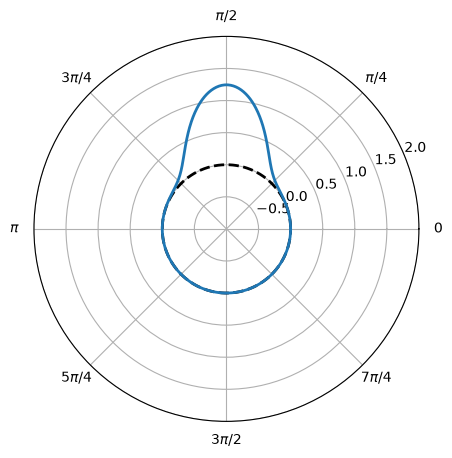

In [4]:
fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={"projection": "polar"})
plot_circular_density(ax, von_mises)

In [5]:
wrapped_cauchy = CBMD.Wrapped_cauchy(np.pi / 2 , 0.75)

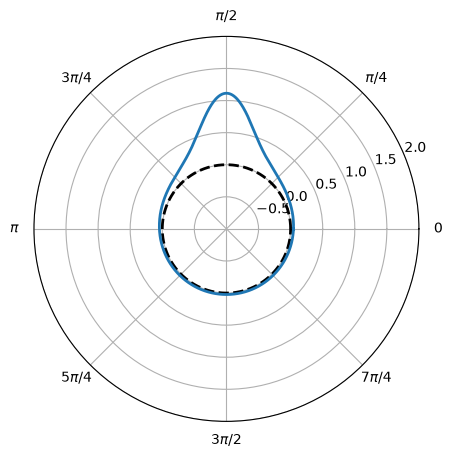

In [6]:
fig, ax = plt.subplots(figsize=(5,5), subplot_kw={"projection": "polar"})
plot_circular_density(ax, wrapped_cauchy)

## 2 dimensions

In [7]:
joint_von_mises = CBMD.Joint_von_mises([0, 0] , [5, 5])

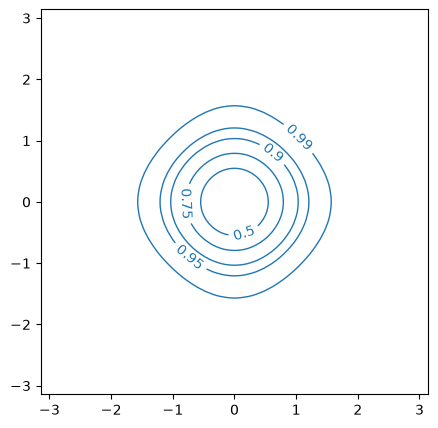

In [8]:
density = joint_von_mises.pdf(coords_2d).reshape(100,100)
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_confidence(ax, density)

In [9]:
von_mises_1 = CBMD.Von_mises(0 , 5)
von_mises_2 = CBMD.Von_mises(0 , 5)

vmwc_circula = CBMD.Wrapped_cauchy_CBMD([von_mises_1, von_mises_2], [1.0, 1.0], [0.5, 0.5])

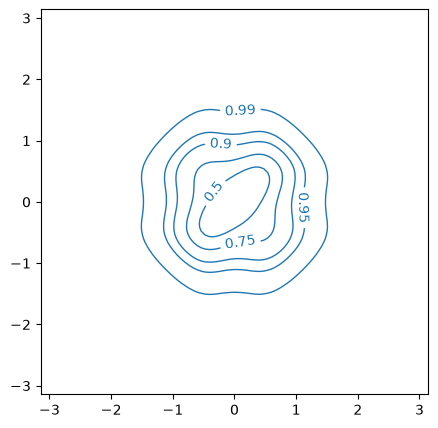

In [10]:
density = vmwc_circula.pdf(coords_2d).reshape(100,100)
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_confidence(ax, density)

## >2 dimensions : mixture models

### Load ALA and CYS models

In [11]:
ALA_model = CBMD.Mixture_model.from_file("VMWC_ALA_model.csv", component_type="VMWC")
PRO_model = CBMD.Mixture_model.from_file("VMWC_PRO_model.csv", component_type="VMWC")


### Generate samples

In [12]:
ALA_sample = ALA_model.sample(size=10)
PRO_sample = PRO_model.sample(size=10)

#### Plot ALA

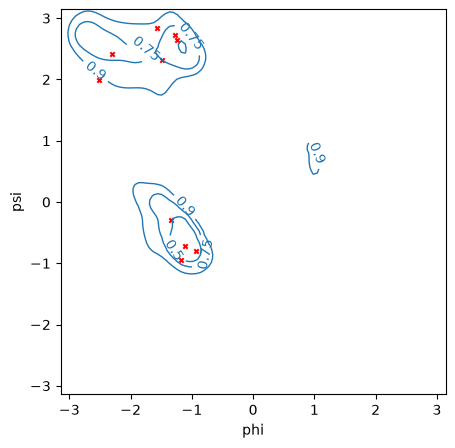

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_single_model(ax, ALA_model, 0, 1, "phi", "psi")
ax.scatter(ALA_sample[:,0], ALA_sample[:,1], s=10, marker='x', color='red')

#### Plot PRO

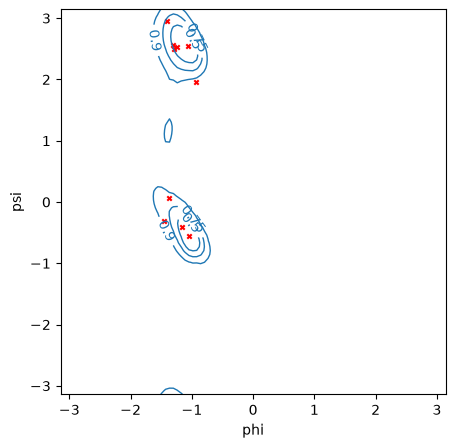

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(5,5))
plot_single_model(ax, PRO_model, 0, 1, "phi", "psi")
ax.scatter(PRO_sample[:,0], PRO_sample[:,1], s=10, marker='x', color='red')

# Part 3 : Conditioning SERALA model on the capping mechanism

## Default SERALA model

### Load SER-ALA pair model

In [15]:
SERALA_model = CBMD.Mixture_model.from_file("VMWC_SER_ALA_model.csv", component_type="VMWC")

### Generate samples

In [16]:
SERALA_sample = SERALA_model.sample(size=10)

### Plot sample

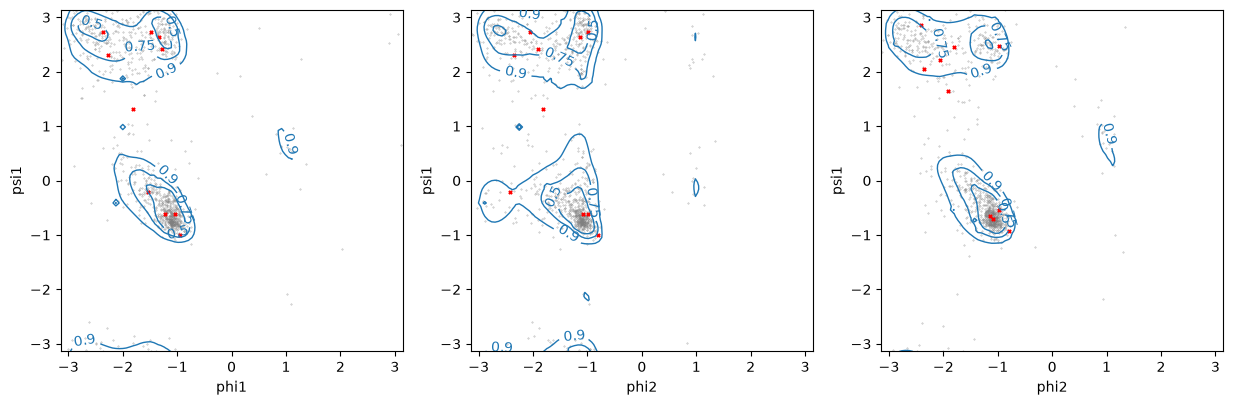

In [17]:
plot_serala_sample(SERALA_model, SERALA_sample)

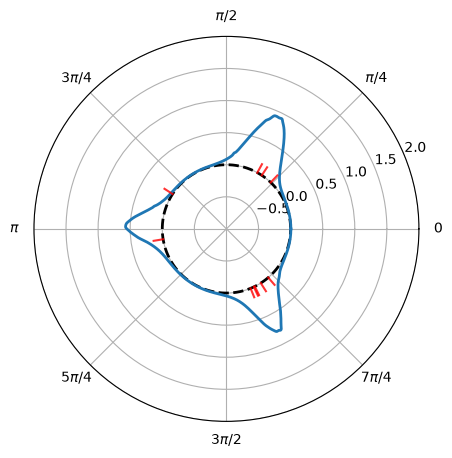

In [18]:
plot_serine_rotamer(SERALA_model, SERALA_sample)

In [19]:
visualize_serala_sample(SERALA_sample, "default")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Condition SERALA model using capping data

### Get capping dataset

In [20]:
#Load SERALA observations
SERALA_df = pd.read_csv("SER_ALA_data")
#Select only observation where SER is not Helix and ALA is Helix (transition)
SERALA_helix_transition_df = SERALA_df[(SERALA_df["dssp1"] != 'H') & (SERALA_df["dssp2"] == 'H')]
SERALA_helix_transition_data = SERALA_helix_transition_df.drop(columns=["dssp1", "dssp2"]).to_numpy()

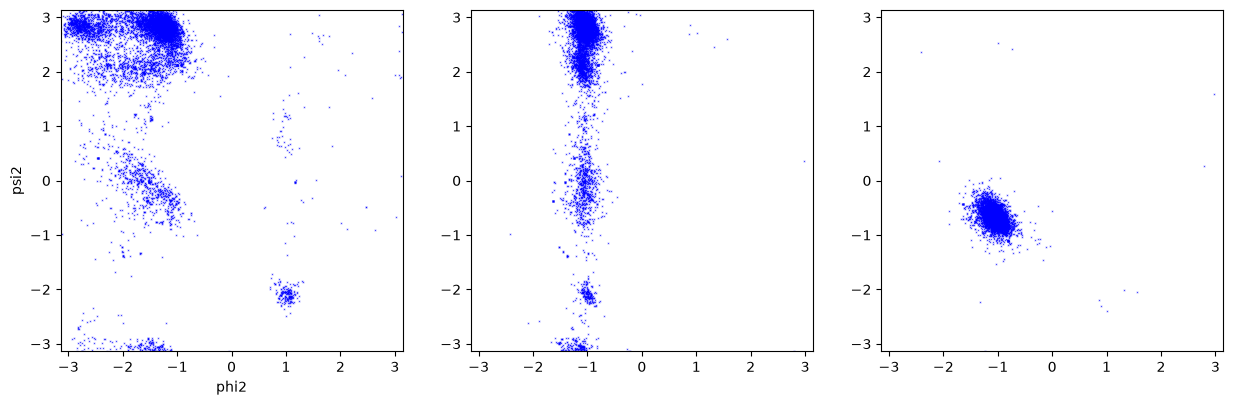

In [21]:
plot_serala_data(SERALA_helix_transition_data)

### Condition SERALA model to capping

In [22]:
def compute_responsibilities(mm, sample):
    resps = np.zeros(shape=(sample.shape[0], len(mm.weights)))

    for i in range(len(mm.weights)):
        weight = mm.weights[i]
        component = mm.components[i]
        resps[:,i] = component.pdf(sample) * weight

    resps_sums = resps.sum(axis=1, keepdims=True)

    resps = resps / resps_sums
        
    return resps

In [23]:
# Compute component responsibility for each datapoint
responsibilities = compute_responsibilities(SERALA_model, SERALA_helix_transition_data)
responsibilities_sum = responsibilities.sum(axis=0)

In [24]:
# Reweight SERALA model using the component responsibilities
SERALA_helix_transition_model = copy.deepcopy(SERALA_model)
SERALA_helix_transition_weights = responsibilities_sum * SERALA_model.weights
SERALA_helix_transition_weights = SERALA_helix_transition_weights / SERALA_helix_transition_weights.sum()
SERALA_helix_transition_model.weights = SERALA_helix_transition_weights

### Generate capping sample

In [25]:
SERALA_helix_transition_sample = SERALA_helix_transition_model.sample(size=10)

### Plot capping sample

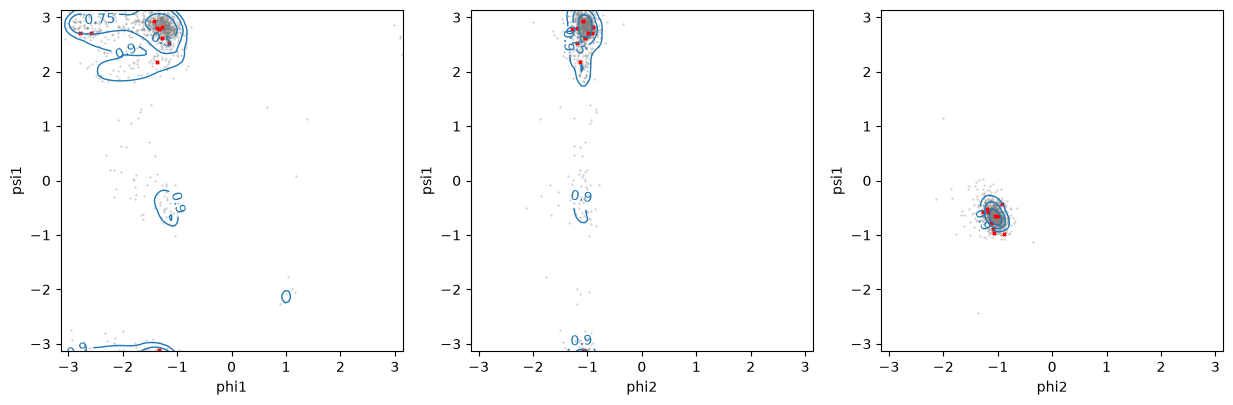

In [26]:
plot_serala_sample(SERALA_helix_transition_model, SERALA_helix_transition_sample)

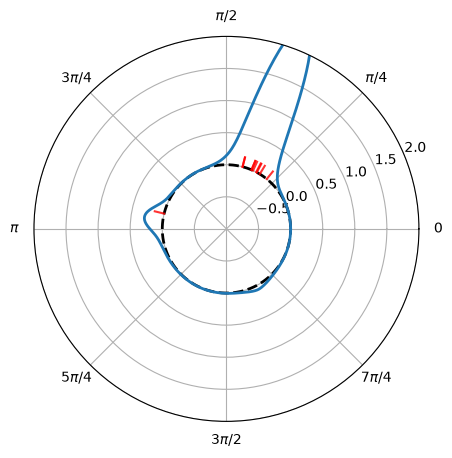

In [27]:
plot_serine_rotamer(SERALA_helix_transition_model, SERALA_helix_transition_sample)

In [28]:
visualize_serala_sample(SERALA_helix_transition_sample, "helix_transition")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.